First Five Rows:
       pickup_datetime  pickup_longitude  pickup_latitude  dropoff_longitude  \
0  2015-01-01 00:00:00        -73.942529        40.759142         -73.938398   
1  2015-01-01 03:00:00        -73.959369        40.718800         -74.004095   
2  2015-01-01 06:00:00        -73.921016        40.772514         -73.916985   
3  2015-01-01 09:00:00        -74.026435        40.778217         -74.072272   
4  2015-01-01 12:00:00        -73.987961        40.691469         -73.940486   

   dropoff_latitude  passenger_count  fare_amount  
0         40.768146                3         3.94  
1         40.716667                4         9.37  
2         40.807075                5         7.57  
3         40.802486                1         8.88  
4         40.572036                2        27.69  

Dataset Shape:
(3000, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  

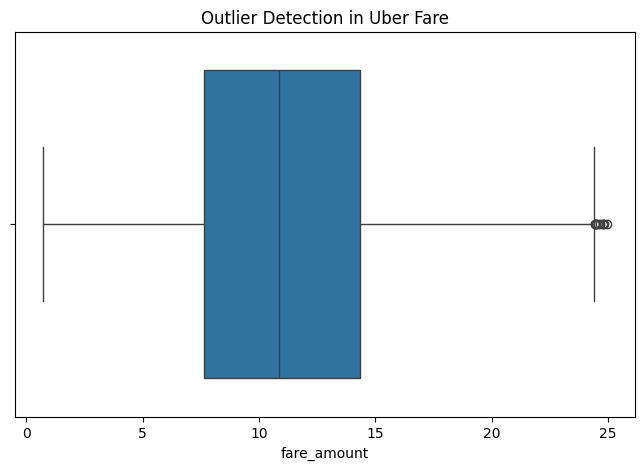

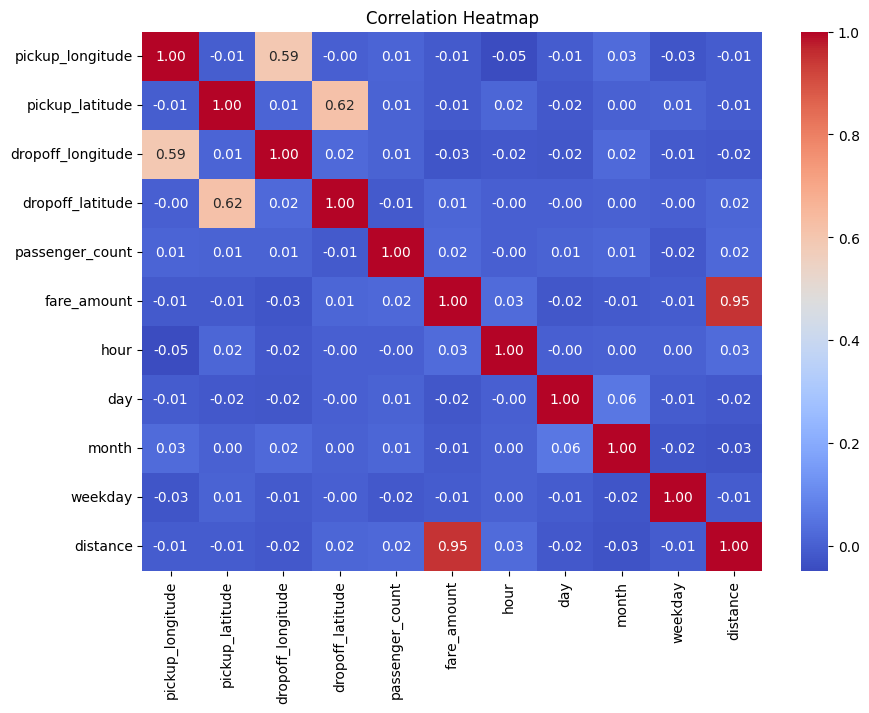


Training Data: (2346, 10)
Testing Data: (587, 10)

 Linear Regression
R2 Score: 0.9104602183039343
RMSE: 1.49885017084
MAE: 1.1834106789696905

 Ridge Regression
R2 Score: 0.9104442265948217
RMSE: 1.4989840113819344
MAE: 1.1835093717565837

 Lasso Regression
R2 Score: 0.910482306610663
RMSE: 1.4986652859558196
MAE: 1.1818967882085003

Model Comparison:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.910460  1.498850  1.183411
1   Ridge Regression  0.910444  1.498984  1.183509
2   Lasso Regression  0.910482  1.498665  1.181897


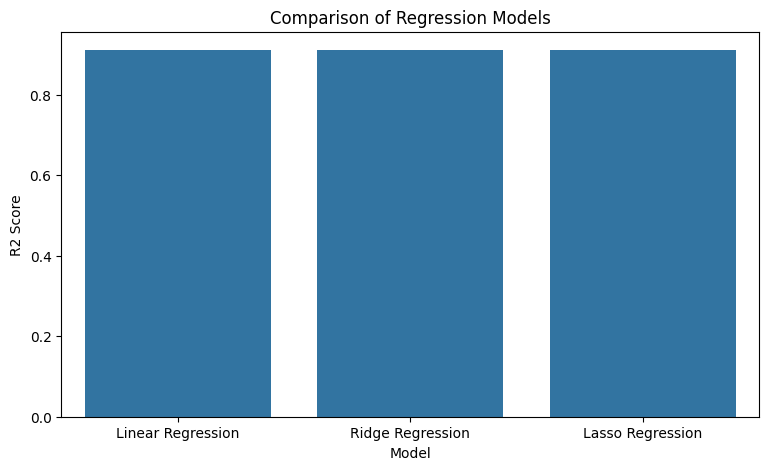

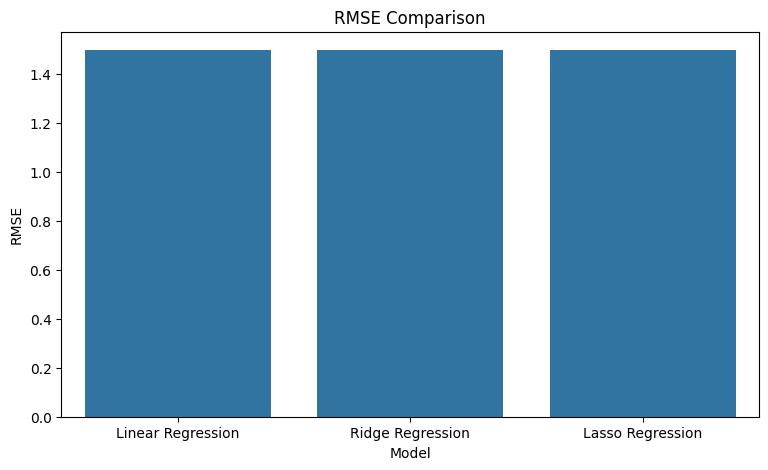

In [1]:
# Experiment: Uber Fare Prediction using Regression

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# Step 2: Load Dataset

df = pd.read_csv("uber.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())


# Step 3: Preprocessing

# Remove unnecessary columns

df.drop(
    columns=['Unnamed: 0', 'key'],
    errors='ignore',
    inplace=True
)

# Handle missing values

df.dropna(inplace=True)

# Convert datetime

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce',
    utc=True
)

df.dropna(inplace=True)

# Extract date and time features

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.dayofweek

# Remove datetime column

df.drop(columns=['pickup_datetime'], inplace=True)

# Remove invalid values

df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6)) &
    (df['pickup_longitude'].between(-75, -72)) &
    (df['dropoff_longitude'].between(-75, -72)) &
    (df['pickup_latitude'].between(39, 42)) &
    (df['dropoff_latitude'].between(39, 42))
].copy()

print("\nAfter Preprocessing:")
print(df.head())

print("\nCleaned Dataset Shape:")
print(df.shape)


# Step 4: Calculate Distance using Haversine Formula

lat1 = np.radians(df['pickup_latitude'])
lat2 = np.radians(df['dropoff_latitude'])

lon1 = np.radians(df['pickup_longitude'])
lon2 = np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

df['distance'] = 6371 * c

# Remove zero-distance rides

df = df[df['distance'] > 0].copy()


# Step 5: Identify Outliers using IQR

Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("\nLower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

# Identify outliers

outliers = df[
    (df['fare_amount'] < lower_limit) |
    (df['fare_amount'] > upper_limit)
]

print("\nNumber of Outliers:", len(outliers))

# Remove outliers

df = df[
    (df['fare_amount'] >= lower_limit) &
    (df['fare_amount'] <= upper_limit)
].copy()


# Step 6: Visualize Outliers

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['fare_amount'])

plt.title("Outlier Detection in Uber Fare")

plt.show()


# Step 7: Check Correlation

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()


# Step 8: Separate Independent and Dependent Variables

X = df.drop(columns=['fare_amount'])

y = df['fare_amount']


# Step 9: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# Step 10: Implement Regression Models

models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Lasso Regression': Lasso(alpha=0.01)
}

results = []

for name, model in models.items():

    pipeline = make_pipeline(
        StandardScaler(),
        model
    )

    # Train Model

    pipeline.fit(X_train, y_train)

    # Predict

    y_pred = pipeline.predict(X_test)

    # Evaluate

    r2 = r2_score(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    mae = mean_absolute_error(y_test, y_pred)

    results.append([
        name,
        r2,
        rmse,
        mae
    ])

    print("\n", name)

    print("R2 Score:", r2)
    print("RMSE:", rmse)
    print("MAE:", mae)


# Step 11: Compare Models

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'R2 Score',
        'RMSE',
        'MAE'
    ]
)

print("\nModel Comparison:")
print(results_df)


# Step 12: Visualize Model Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Comparison of Regression Models")

plt.ylabel("R2 Score")

plt.show()


# Step 13: RMSE Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison")

plt.ylabel("RMSE")

plt.show()